In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sys
sys.path.append("../")
from src.synthetic_catalog_creation import synthetic_catalog_creation
from src.catalog_analysis import catalog_to_stress_and_instability
from src.M0_estimation import random_normals
from src.M0_estimation import instability_PDF
from src.plot import plot_unitmohr_with_coulomb
from src.plot import plot_instability_PDF

In [2]:
### input parameters ###
sigma_model = np.array([[1,0,0], [0,-1,0], [0,0,0]])
M0 = -2
Mc = 2
friction_model = 0.3
focmech_uncertainty = np.array([15, 34])    # degree

stressinverse_dir = "../../Stressinverse_1.1.3"

# relationship between instability and b-value
def model_i_to_b(instability, model_type):
    if model_type == "exp":
        return 1.1 - 0.4 * np.exp((instability - 1) / 0.4)
    if model_type == "linear":
        return np.where(
            instability >= 0.9,
            4 * (1 - instability) + 0.7,
            1.1
        )

In [3]:
columns = ["magnitude", "strike", "dip", "rake", "Snn", "Sne", "Snd", "See", "Sed", "Sdd", "R"]

catalog_M0, catalog_Mc = [
    pd.DataFrame(columns=columns)
    for _ in range(2)
]

In [4]:
### catalog creation (M0) ###
strike_orig, dip_orig, rake_orig, magnitude = synthetic_catalog_creation(
                                                sigma_model,
                                                model_i_to_b,
                                                "exp",
                                                M0,
                                                M0,
                                                friction_model,
                                                N_earthquake=10**4,
                                                N_subgroup=10**4
                                                )

normal_stress, shear_stress, _ = catalog_to_stress_and_instability(
    sigma_model, friction_model, strike_orig, dip_orig, rake_orig
)

fig, ax = plot_unitmohr_with_coulomb(normal_stress, shear_stress, friction_model)

fig.savefig(f"../figures/M0estimation/mohr_M0={M0}.png", bbox_inches="tight", dpi=300)

In [5]:
### catalog creation (Mc) ###
## same as catalog_no_error_exp
strike_orig, dip_orig, rake_orig, magnitude = synthetic_catalog_creation(
                                                sigma_model,
                                                model_i_to_b,
                                                "exp",
                                                M0,
                                                Mc,
                                                friction_model,
                                                N_earthquake=10**4,
                                                N_subgroup=10**6
                                                )

normal_stress, shear_stress, instability = catalog_to_stress_and_instability(
    sigma_model, friction_model, strike_orig, dip_orig, rake_orig
)

fig, ax = plot_unitmohr_with_coulomb(normal_stress, shear_stress, friction_model)

fig.savefig(f"../figures/M0estimation/mohr_Mc={Mc}.png", bbox_inches="tight", dpi=300)

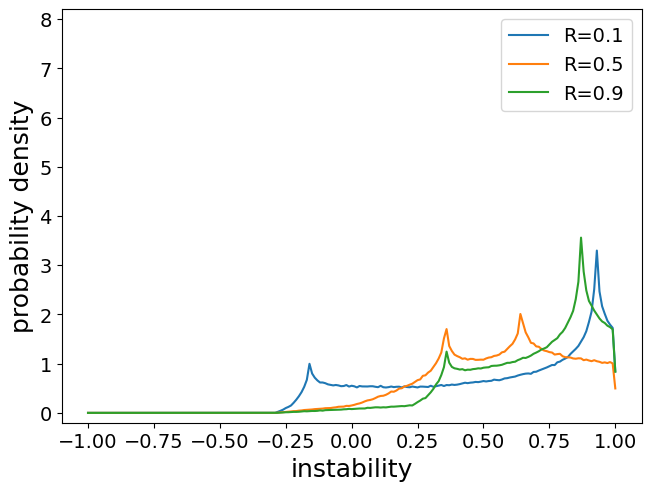

In [13]:
N = 10**6
n = random_normals(N, seed=1000)

fig, ax = plt.subplots(constrained_layout=True)
LEGEND_SIZE = 14
for _, R in enumerate(np.arange(0.1, 1, 0.4)):
    center, PDF = instability_PDF(R, friction_model, n)
    plot_instability_PDF(
        ax,
        center,
        PDF,
        label=f"R={R:.1f}"
    )
ax.set_ylim(-0.2, 8.2)
ax.legend(fontsize=LEGEND_SIZE)
fig.savefig(f"../figures/M0estimation/instability_PDF_M0={M0}.png", bbox_inches="tight", dpi=300)

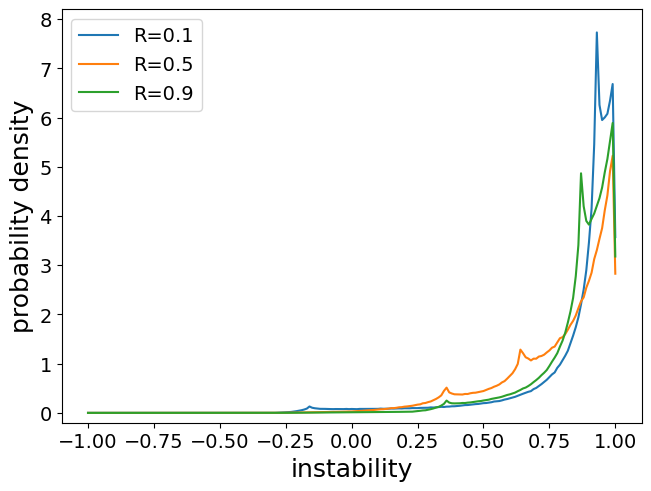

In [12]:
N = 10**6
n = random_normals(N, seed=1000)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(constrained_layout=True)
LEGEND_SIZE = 14
for _, R in enumerate(np.arange(0.1, 1, 0.4)):
    center, PDF = instability_PDF(R, friction_model, n)
    dI = center[1] - center[0]
    evolution = 10**(-model_i_to_b(center, "exp") * (Mc-M0))
    P = PDF * evolution / (np.sum(PDF * evolution) * dI)
    plot_instability_PDF(
        ax,
        center,
        P,
        label=f"R={R:.1f}"
    )
ax.set_ylim(-0.2, 8.2)
ax.legend(fontsize=LEGEND_SIZE)
fig.savefig(f"../figures/M0estimation/instability_PDF_Mc={Mc}.png", bbox_inches="tight", dpi=300)

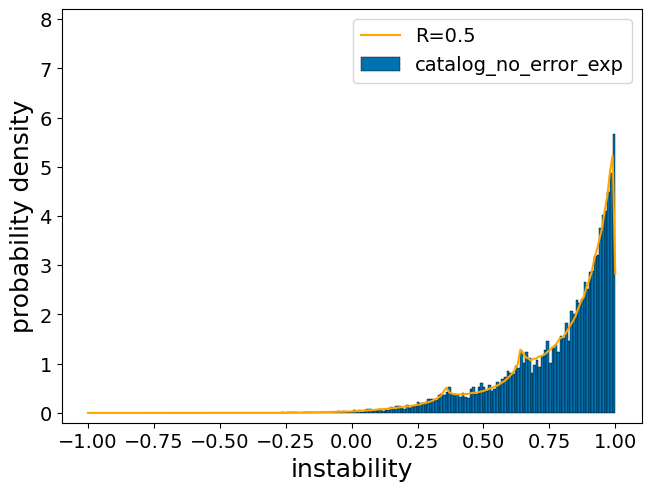

In [14]:
fig, ax = plt.subplots(constrained_layout=True)

R = 0.5
center, PDF = instability_PDF(R, friction_model, n)
dI = center[1] - center[0]
evolution = 10**(-model_i_to_b(center, "exp") * (Mc-M0))
P = PDF * evolution / (np.sum(PDF * evolution) * dI)
plot_instability_PDF(
    ax,
    center,
    P,
    label=f"R={R:.1f}",
    color="orange"
)

plt.hist(
    instability,
    bins=np.linspace(-1, 1, 200),
    edgecolor="k",
    linewidth=0.3,
    label="catalog_no_error_exp",
    color="#0072B2",
    density=True
)

ax.set_ylim(-0.2, 8.2)
ax.legend(fontsize=LEGEND_SIZE)
fig.savefig(f"../figures/M0estimation/comparison_with_catalog.png", bbox_inches="tight", dpi=300)